In [ ]:
import sys

print(sys.executable)
print(sys.version)

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import nltk

print("All libraries imported successfully!")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
NumPy: 2.5.4
Pandas: 3.1.0
Scikit-learn: 1.9.1


In [4]:
import pandas as pd

file_path = "../data/raw/logical_fallacy_dataset.xlsx"

excel = pd.ExcelFile(file_path)

print(excel.sheet_names)

['README', 'Dataset', 'Label Guide', 'Excluded - Review']


In [5]:
df = pd.read_excel(file_path, sheet_name="Dataset")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (17866, 21)


,id,argument,fallacies,num_fallacies,split,Slippery Slope,Appeal to Authority,Bandwagon / Popularity,Hasty Generalization,False Cause / Causality,...,Composition,False Dilemma,Ad Hominem,Equivocation,Circular Reasoning,Straw Man,Red Herring,Appeal to Ignorance,Affirming the Consequent,Denying the Antecedent
0,1,"A politician declares: 'Recently, there have b...",Hasty Generalization; Appeal to Emotion,2,train,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,2,A commentator claims: 'If we allow students to...,Slippery Slope; Ad Hominem,2,train,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,3,A famous actor in a commercial says: 'I drink ...,Appeal to Authority; False Cause / Causality,2,train,0,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,4,A concerned parent says: 'I heard about a teen...,Hasty Generalization; Appeal to Emotion,2,train,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,5,"As a renowned scientist, Dr. Smith claims that...",Appeal to Authority,1,train,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# 1. Dataset Audit

The objective of this section is to investigate the structural
integrity and reliability of the dataset before beginning
preprocessing and model development.

We will investigate:

1. Missing values
2. Duplicate observations
3. Target label consistency
4. Distribution of labels
5. Distribution of train, validation and test splits

In [ ]:
# Check missing values

missing_values = df.isnull().sum()

print(missing_values)

# Total missing values

print("Total missing values:", df.isnull().sum().sum())

id                          0
argument                    0
fallacies                   0
num_fallacies               0
split                       0
Slippery Slope              0
Appeal to Authority         0
Bandwagon / Popularity      0
Hasty Generalization        0
False Cause / Causality     0
Appeal to Emotion           0
Composition                 0
False Dilemma               0
Ad Hominem                  0
Equivocation                0
Circular Reasoning          0
Straw Man                   0
Red Herring                 0
Appeal to Ignorance         0
Affirming the Consequent    0
Denying the Antecedent      0
dtype: int64
Total missing values: 0


In [9]:
# Check duplicate rows

print("Duplicate rows:", df.duplicated().sum())

# Check duplicate arguments

print("Duplicate arguments:", df["argument"].duplicated().sum())

# Check duplicate IDs

print("Duplicate IDs:", df["id"].duplicated().sum())

Duplicate rows: 0
Duplicate arguments: 0
Duplicate IDs: 0


In [35]:
label_cols = df.columns[5:].tolist()

calculated_counts = df[label_cols].sum(axis=1)

mismatches = df["num_fallacies"] != calculated_counts

print("Number of mismatches:", mismatches.sum())

Number of mismatches: 0


In [36]:
def get_labels_from_columns(row):
    return set(
        col for col in label_cols
        if row[col] == 1
    )


def get_labels_from_string(value):
    return set(
        label.strip()
        for label in value.split(";")
    )


mismatches = []

for idx, row in df.iterrows():

    labels_from_columns = get_labels_from_columns(row)

    labels_from_string = get_labels_from_string(row["fallacies"])

    if labels_from_columns != labels_from_string:
        mismatches.append(idx)

print("Label inconsistencies:", len(mismatches))

Label inconsistencies: 0


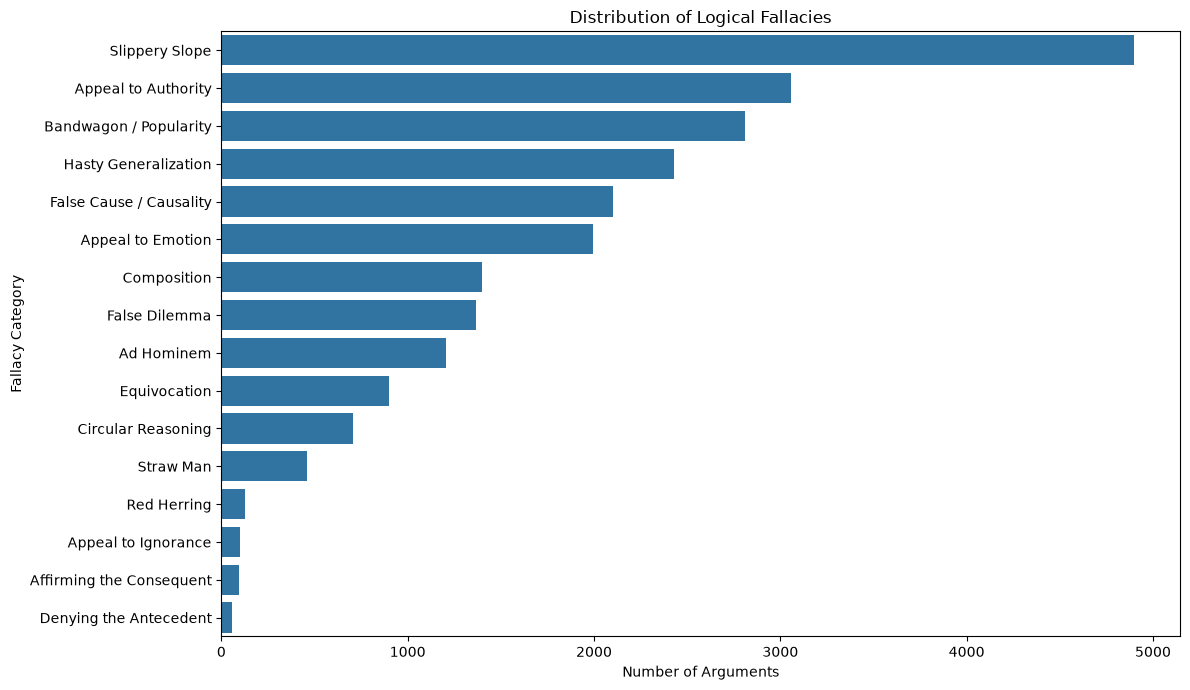

In [38]:
label_counts = df[label_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=label_counts.values,
    y=label_counts.index
)

plt.title("Distribution of Logical Fallacies")
plt.xlabel("Number of Arguments")
plt.ylabel("Fallacy Category")

plt.tight_layout()
plt.show()

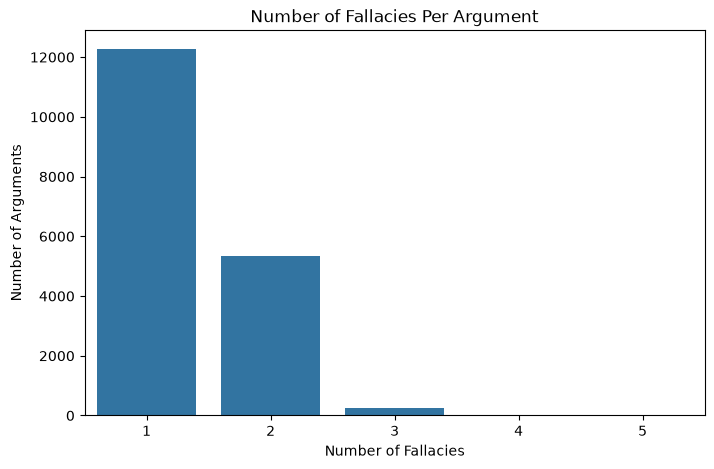

In [39]:
label_distribution = df["num_fallacies"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=label_distribution.index,
    y=label_distribution.values
)

plt.title("Number of Fallacies Per Argument")
plt.xlabel("Number of Fallacies")
plt.ylabel("Number of Arguments")

plt.show()

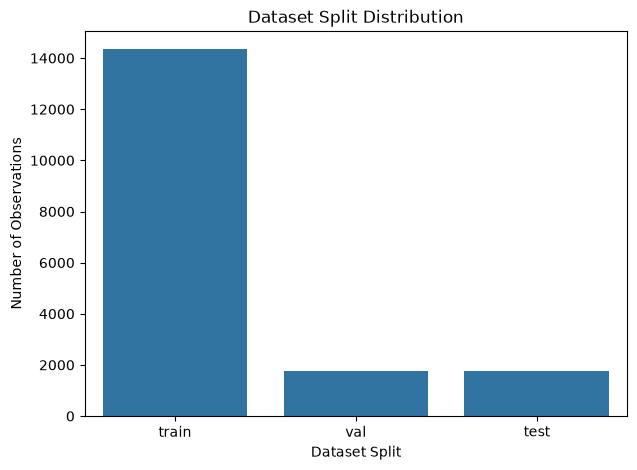

In [40]:
split_counts = df["split"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=split_counts.index,
    y=split_counts.values
)

plt.title("Dataset Split Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Observations")

plt.show()

In [41]:
split_label_counts = df.groupby("split")[label_cols].sum().T
test_obs = sum(df["split"] == "test")
test_obs
two_fal = sum(df['num_fallacies'] == 2)
two_fal 
max_fal = max(df['num_fallacies'])
max_fal
cols = df.columns[5:]
fal_cnt = df[cols].sum(axis = 0)
fal_cnt.sort_values(ascending=False)
fal_cnt
trn_fal_cnt = df.groupby('split')[cols].sum()
trn_fal_cnt


,Slippery Slope,Appeal to Authority,Bandwagon / Popularity,Hasty Generalization,False Cause / Causality,Appeal to Emotion,Composition,False Dilemma,Ad Hominem,Equivocation,Circular Reasoning,Straw Man,Red Herring,Appeal to Ignorance,Affirming the Consequent,Denying the Antecedent
split,,,,,,,,,,,,,,,,
test,485,316,281,207,215,208,131,146,119,86,74,35,7,7,15,8
train,3925,2462,2268,2008,1675,1581,1118,1080,957,733,559,384,103,85,70,44
val,490,279,262,213,211,207,151,139,129,81,73,39,19,10,12,5
